# palm 50장 손 마스크 자동 검출 — rembg (Colab T4)

**목적**: 합성 v3에서 알약을 손 영역 안에만 배치하기 위한 마스크 생성.

**환경**: rembg 2.0.50 + onnxruntime-gpu 1.16.3 + numpy 1.26.4 + pillow 10.4.0 + opencv-python 4.10.0.84

(세션 41 검증 완료 박제값 — 단순 `pip install`은 의존성 충돌로 cv2 import 깨짐)

**모델**: isnet-general-use (사용자 박제, 알약 누끼에서 검증)


## 1. 현재 Colab 환경 진단

In [1]:
import sys
print(f'Python: {sys.version.split()[0]}')
print()
print('[현재 패키지 버전]')
for pkg in ['numpy', 'cv2', 'PIL']:
    try:
        if pkg == 'PIL':
            import PIL
            v = PIL.__version__
        elif pkg == 'cv2':
            import cv2
            v = cv2.__version__
        else:
            mod = __import__(pkg)
            v = getattr(mod, '__version__', '?')
        print(f'  {pkg:10s}: {v}')
    except Exception as e:
        print(f'  {pkg:10s}: 에러 ({type(e).__name__})')

print('\n[목표 (정본)]')
print('  numpy  : 1.26.4')
print('  cv2    : 4.10.0')
print('  PIL    : 10.4.0')

import subprocess
try:
    out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                         capture_output=True, text=True, timeout=5).stdout.strip()
    print(f'\n[GPU] {out}')
except Exception:
    print('\n[GPU] nvidia-smi 사용 불가 (T4 런타임 확인 필요)')


Python: 3.11.13

[현재 패키지 버전]
  numpy     : 2.0.2
  cv2       : 4.12.0
  PIL       : 11.2.1

[목표 (정본)]
  numpy  : 1.26.4
  cv2    : 4.10.0
  PIL    : 10.4.0

[GPU] Tesla T4, 15360 MiB


## 2. 정본 환경 정정 (numpy/pillow/opencv)

In [2]:
!pip install --quiet \
  "numpy==1.26.4" \
  "opencv-python==4.10.0.84" \
  "pillow==10.4.0"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 84.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 56.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.


## 3. 정정 결과 검증 (모듈 캐시 청소)

In [1]:
import sys
for mod_name in list(sys.modules.keys()):
    if any(mod_name.startswith(p) for p in ['numpy', 'cv2', 'PIL']):
        del sys.modules[mod_name]

import numpy, cv2, PIL
print('[정정 후]')
print(f'  numpy : {numpy.__version__}')
print(f'  cv2   : {cv2.__version__}')
print(f'  PIL   : {PIL.__version__}')


[정정 후]
  numpy : 1.26.4
  cv2   : 4.10.0
  PIL   : 10.4.0


/tmp/ipython-input-1-2698870329.py:6: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy, cv2, PIL


## 4. opencv-python-headless 제거 (cv2 충돌 방지)

Colab 기본 환경에 opencv-python-headless가 깔려있을 수 있음. opencv-python과 동시 존재 시 cv2 import 충돌.


In [2]:
!pip show opencv-python opencv-python-headless 2>&1 | head -20


Name: opencv-python
Version: 4.10.0.84
Summary: Wrapper package for OpenCV python bindings.
Home-page: https://github.com/opencv/opencv-python
Author: 
Author-email: 
License: Apache 2.0
Location: /usr/local/lib/python3.11/dist-packages
Requires: numpy
Required-by: dopamine_rl
---
Name: opencv-python-headless
Version: 4.12.0.88
Summary: Wrapper package for OpenCV python bindings.
Home-page: https://github.com/opencv/opencv-python
Author: 
Author-email: 
License: Apache 2.0
Location: /usr/local/lib/python3.11/dist-packages
Requires: numpy


In [3]:
!pip uninstall -y opencv-python-headless
!pip install --force-reinstall --no-deps "opencv-python==4.10.0.84"


Found existing installation: opencv-python-headless 4.12.0.88
Uninstalling opencv-python-headless-4.12.0.88:
  Successfully uninstalled opencv-python-headless-4.12.0.88
  Using cached opencv_python-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (62.5 MB)
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.10.0.84
    Uninstalling opencv-python-4.10.0.84:
      Successfully uninstalled opencv-python-4.10.0.84


## 5. cv2 정합 검증

In [1]:
import sys
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith('cv2'):
        del sys.modules[mod_name]

import cv2
print(f'cv2: {cv2.__version__}')
print(f'cv2 path: {cv2.__file__}')
print(f'BORDER_DEFAULT: {cv2.BORDER_DEFAULT}  (rembg 의존)')
print(f'MORPH_ELLIPSE:  {cv2.MORPH_ELLIPSE}   (rembg 의존)')


cv2: 4.10.0
cv2 path: /usr/local/lib/python3.11/dist-packages/cv2/__init__.py
BORDER_DEFAULT: 4  (rembg 의존)
MORPH_ELLIPSE:  2   (rembg 의존)


## 6. rembg + onnxruntime-gpu 설치 (numpy 1 호환 박제값)


In [2]:
!pip install --quiet "rembg==2.0.50" "onnxruntime-gpu==1.16.3"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.1/157.1 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 68.9 MB/s eta 0:00:00


## 7. rembg 설치 후 환경 점검

In [3]:
!pip list 2>&1 | grep -iE "^(numpy|pillow|opencv|rembg|onnxruntime|pymatting) " | sort


numpy                                 2.0.2
onnxruntime                           1.25.1
pillow                                10.4.0
PyMatting                             1.1.15
rembg                                 2.0.50


## 8. 충돌 패키지 정리 + onnxruntime-gpu 재설치

rembg 설치가 onnxruntime (CPU) / opencv-python-headless / opencv-contrib-python을 다시 끌어옴 → 제거 후 정본 force-reinstall.


In [4]:
# 1) 부주의 설치된 것들 제거
!pip uninstall -y opencv-python-headless opencv-contrib-python onnxruntime

# 2) opencv-python 4.10 강제 재설치
!pip install --force-reinstall --no-deps "opencv-python==4.10.0.84"

# 3) numpy + pillow 정본 복구 (rembg 의존성으로 다시 끌어올린 경우 대비)
!pip install --no-deps "numpy==1.26.4" "pillow==10.4.0"

# 4) onnxruntime-gpu force-reinstall (CPU 버전 제거 후 재설치 필수)
!pip install --force-reinstall --no-deps "onnxruntime-gpu==1.16.3"


Found existing installation: opencv-python-headless 4.13.0.92
Uninstalling opencv-python-headless-4.13.0.92:
  Successfully uninstalled opencv-python-headless-4.13.0.92
Found existing installation: opencv-contrib-python 4.11.0.86
Uninstalling opencv-contrib-python-4.11.0.86:
  Successfully uninstalled opencv-contrib-python-4.11.0.86
Found existing installation: onnxruntime 1.25.1
Uninstalling onnxruntime-1.25.1:
  Successfully uninstalled onnxruntime-1.25.1
  Using cached opencv_python-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (62.5 MB)
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.10.0.84
    Uninstalling opencv-python-4.10.0.84:
      Successfully uninstalled opencv-python-4.10.0.84


  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2


  Using cached onnxruntime_gpu-1.16.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.3 kB)
Using cached onnxruntime_gpu-1.16.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (157.1 MB)
  Attempting uninstall: onnxruntime-gpu
    Found existing installation: onnxruntime-gpu 1.16.3
    Uninstalling onnxruntime-gpu-1.16.3:
      Successfully uninstalled onnxruntime-gpu-1.16.3


KeyboardInterrupt: 

## 9. 최종 환경 + rembg 검증

In [1]:
import sys
for mod_name in list(sys.modules.keys()):
    if any(mod_name.startswith(p) for p in ['numpy', 'PIL', 'cv2', 'rembg', 'onnxruntime', 'pymatting']):
        del sys.modules[mod_name]

import numpy, PIL, cv2
print('[정본 환경]')
print(f'  numpy : {numpy.__version__}  (목표 1.26.4)')
print(f'  PIL   : {PIL.__version__}    (목표 10.4.0)')
print(f'  cv2   : {cv2.__version__}    (목표 4.10.0)')

import onnxruntime
print(f'\n[onnxruntime]')
print(f'  version   : {onnxruntime.__version__}  (목표 1.16.3)')
print(f'  providers : {onnxruntime.get_available_providers()}')
assert 'CUDAExecutionProvider' in onnxruntime.get_available_providers(), 'CUDA 미지원'

import rembg
from rembg import remove, new_session
print(f'\n[rembg]')
print(f'  version : {rembg.__version__}  (목표 2.0.50)')
print(f'  remove, new_session import OK')


/tmp/ipython-input-1-1254868246.py:6: UserWarning: The NumPy module was reloaded (imported a second time). This can in some cases result in small but subtle issues and is discouraged.
  import numpy, PIL, cv2


[정본 환경]
  numpy : 1.26.4  (목표 1.26.4)
  PIL   : 10.4.0    (목표 10.4.0)
  cv2   : 4.10.0    (목표 4.10.0)

[onnxruntime]
  version   : 1.16.3  (목표 1.16.3)
  providers : ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']

[rembg]
  version : 2.0.50  (목표 2.0.50)
  remove, new_session import OK


## 10. 작업 디렉토리 + 한글 폰트 + 헬퍼

In [2]:
from pathlib import Path
import numpy as np
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import time, os, zipfile

# 한글 폰트 (apt-get nanum)
os.system('apt-get install -y -qq fonts-nanum > /dev/null')
NANUM_PATH = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(NANUM_PATH):
    fm.fontManager.addfont(NANUM_PATH)
    plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

PALM_DIR = Path('/content/palm_hand')
MASK_DIR = Path('/content/palm_hand_masks')
MASK_DIR.mkdir(exist_ok=True)

print('준비 완료')


준비 완료


## 11. palm_hand_50.zip 업로드 + 압축 해제

**먼저 로컬에서 zip 만들기** (PowerShell):

```powershell
Compress-Archive -Path D:\pill_detection\synthetic_bg\palm_hand\* -DestinationPath D:\pill_detection\palm_hand_50.zip -Force
```

그 다음 Colab 사이드바 (왼쪽 폴더 아이콘) → 우클릭 → '파일 업로드' → palm_hand_50.zip 선택.


In [3]:
ZIP_PATH = '/content/palm_hand_50.zip'
assert os.path.exists(ZIP_PATH), f'{ZIP_PATH} 없음. 사이드바에서 zip 업로드.'

if not PALM_DIR.exists() or not list(PALM_DIR.glob('*')):
    PALM_DIR.mkdir(exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(PALM_DIR)

palm_paths = sorted(PALM_DIR.glob('palm_*.png')) + sorted(PALM_DIR.glob('palm_*.jpg'))
print(f'palm 이미지: {len(palm_paths)}장')


palm 이미지: 50장


## 12. 단일 sanity — palm_002 (가장 어려운 케이스)

색상 기반에서 마스크 100% (배경까지 잡힘) 떴던 컷. rembg가 정상 분리하는지 확인.


100%|████████████████████████████████████████| 179M/179M [00:00<00:00, 197GB/s]


EP Error /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:1193 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library libonnxruntime_providers_tensorrt.so with error: libcudnn.so.8: cannot open shared object file: No such file or directory
 when using ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']
Falling back to ['CUDAExecutionProvider', 'CPUExecutionProvider'] and retrying.
모델 로드: isnet-general-use
테스트: palm_002.png ((768, 1344))
처리 시간: 4.63초


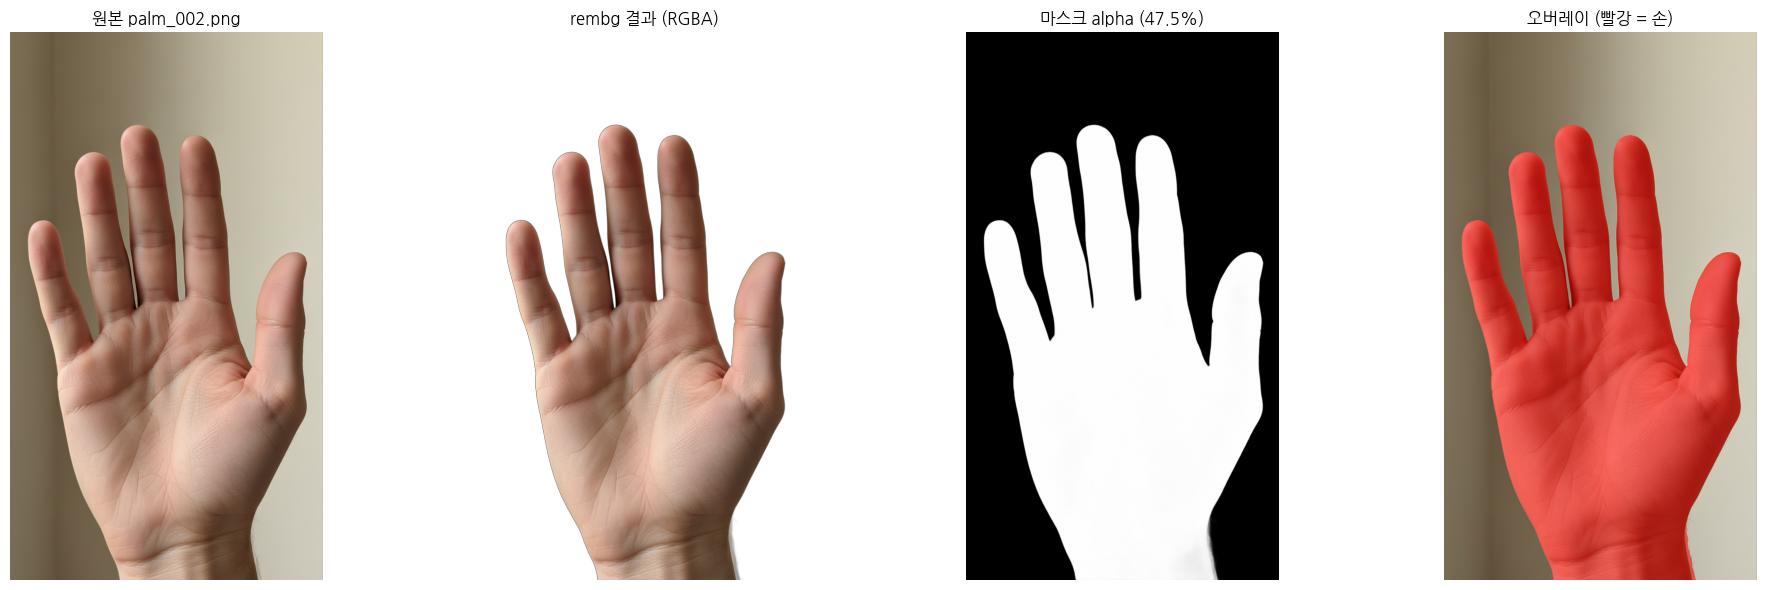


통과 기준: 빨간 영역이 손에만, 흰 배경에 X
커버리지 정상 범위: 30~60%


In [4]:
MODEL_NAME = 'isnet-general-use'   # 박제: 사용자가 알약 누끼에서 검증
session = new_session(MODEL_NAME)
print(f'모델 로드: {MODEL_NAME}')

test_path = PALM_DIR / 'palm_002.png'
if not test_path.exists():
    test_path = next((p for p in palm_paths if 'palm_002' in p.name), palm_paths[1])

img = Image.open(test_path)
print(f'테스트: {test_path.name} ({img.size})')

# Warmup
_ = remove(img, session=session)

t0 = time.time()
result = remove(img, session=session)
print(f'처리 시간: {time.time()-t0:.2f}초')

rgba = np.array(result)
mask = rgba[:, :, 3]
coverage = (mask > 128).sum() / (mask.shape[0] * mask.shape[1]) * 100

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
axes[0].imshow(img); axes[0].set_title(f'원본 {test_path.name}'); axes[0].axis('off')
axes[1].imshow(rgba); axes[1].set_title('rembg 결과 (RGBA)'); axes[1].axis('off')
axes[2].imshow(mask, cmap='gray'); axes[2].set_title(f'마스크 alpha ({coverage:.1f}%)'); axes[2].axis('off')

rgb = np.array(img.convert('RGB'))
overlay = rgb.copy()
overlay[mask > 128] = (overlay[mask > 128] * 0.5 + np.array([255, 0, 0]) * 0.5).astype(np.uint8)
axes[3].imshow(overlay); axes[3].set_title('오버레이 (빨강 = 손)'); axes[3].axis('off')

plt.tight_layout()
plt.show()

print(f'\n통과 기준: 빨간 영역이 손에만, 흰 배경에 X')
print(f'커버리지 정상 범위: 30~60%')


## 13. (선택) 모델 변경 시도

isnet-general-use 결과 미흡하면 다른 모델 시도 후 셀 12 재실행.


In [ ]:
# MODEL_NAME = 'u2net_human_seg'  # 사람/손 특화
# MODEL_NAME = 'u2net'              # 범용
# MODEL_NAME = 'silueta'            # 실루엣

FINAL_MODEL = 'isnet-general-use'   # ← sanity 통과한 모델
session = new_session(FINAL_MODEL)
print(f'최종 모델: {FINAL_MODEL}')


## 14. 전체 50장 마스크 생성

In [5]:
from tqdm.auto import tqdm

coverages = []
failed = []

t0 = time.time()
for p in tqdm(palm_paths, desc='rembg'):
    try:
        img = Image.open(p)
        result = remove(img, session=session)
        rgba = np.array(result)
        mask = rgba[:, :, 3]

        mask_bin = (mask > 128).astype(np.uint8) * 255
        out_path = MASK_DIR / (p.stem + '_mask.png')
        Image.fromarray(mask_bin).save(out_path)

        coverage = (mask_bin == 255).sum() / mask_bin.size * 100
        coverages.append((p.stem, coverage))
    except Exception as e:
        failed.append((p.name, str(e)))

print(f'\n완료: {len(coverages)}장 / 실패 {len(failed)} / {time.time()-t0:.0f}초')

if coverages:
    cs = [c for _, c in coverages]
    print(f'\n커버리지: mean {np.mean(cs):.1f}% / std {np.std(cs):.1f}% / min {min(cs):.1f}% / max {max(cs):.1f}%')

    suspicious = [(n, c) for n, c in sorted(coverages, key=lambda x: x[1]) if c < 15 or c > 75]
    print(f'\n검수 권고 ({len(suspicious)}장 — < 15% or > 75%):')
    for n, c in suspicious:
        print(f'  {n}: {c:.1f}%')


rembg:   0%|          | 0/50 [00:00<?, ?it/s]


완료: 50장 / 실패 0 / 212초

커버리지: mean 37.3% / std 21.4% / min 0.0% / max 71.5%

검수 권고 (11장 — < 15% or > 75%):
  palm_050: 0.0%
  palm_033: 0.2%
  palm_036: 0.2%
  palm_032: 0.7%
  palm_043: 1.0%
  palm_038: 1.0%
  palm_040: 1.1%
  palm_031: 1.2%
  palm_034: 1.9%
  palm_039: 2.8%
  palm_037: 3.3%


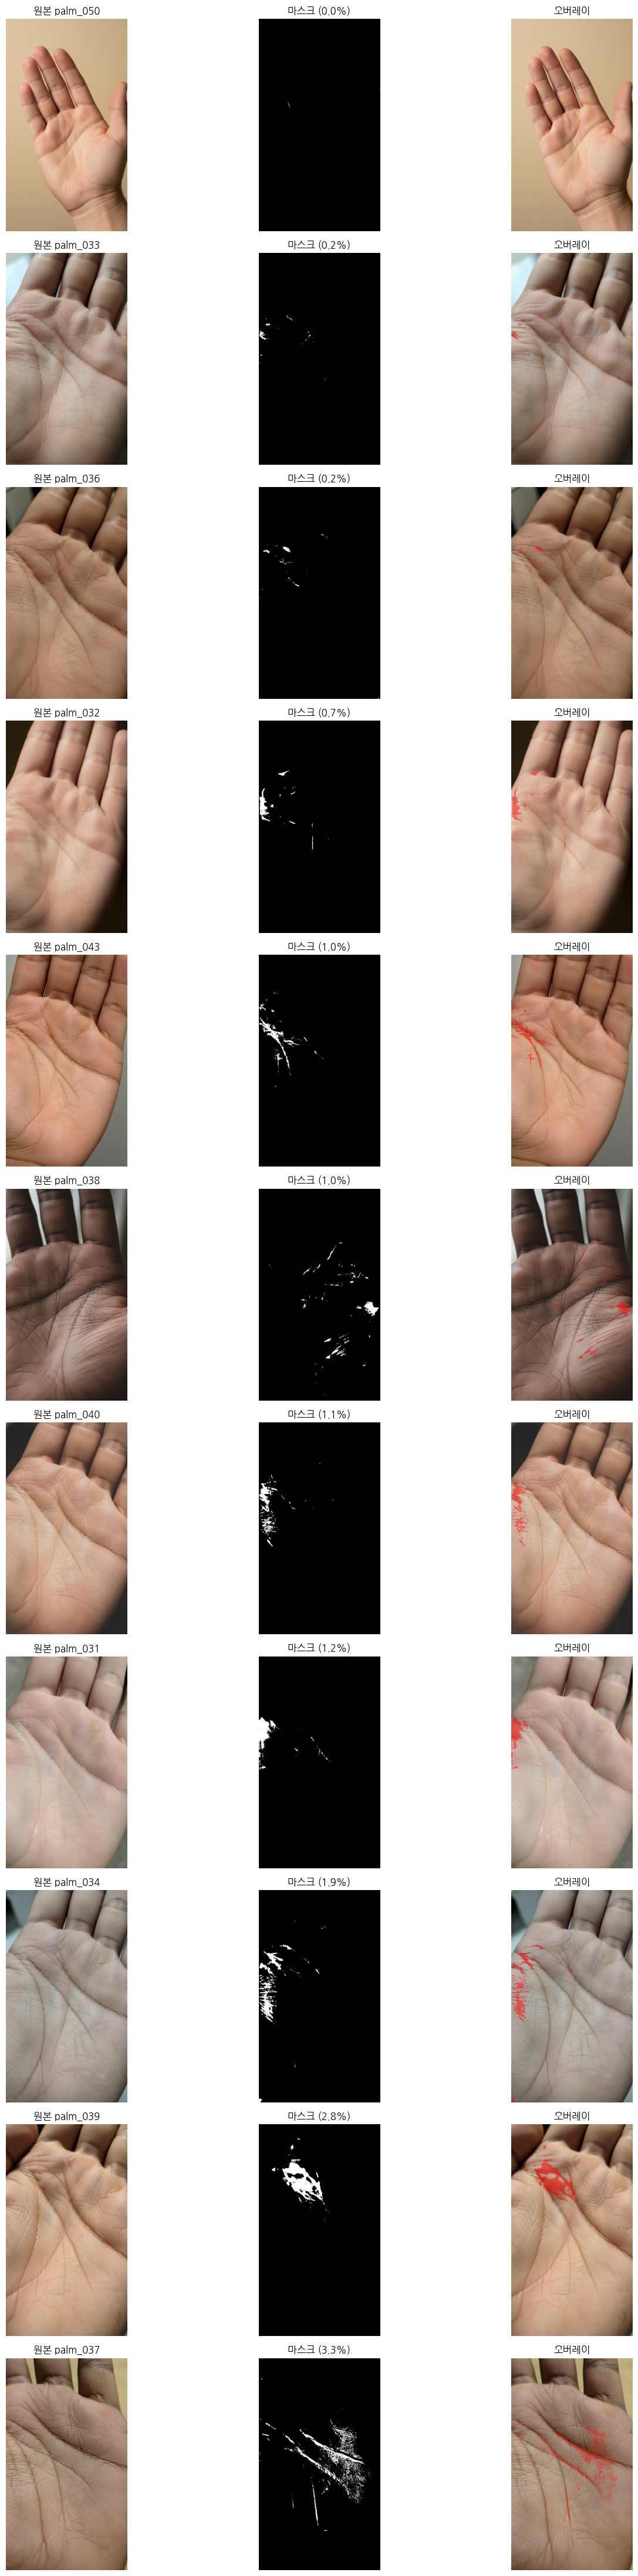

In [7]:
# 의심 케이스 11장 시각화
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

suspicious_names = [
    'palm_050', 'palm_033', 'palm_036', 'palm_032', 'palm_043',
    'palm_038', 'palm_040', 'palm_031', 'palm_034', 'palm_039', 'palm_037'
]

n = len(suspicious_names)
fig, axes = plt.subplots(n, 3, figsize=(15, 4 * n))

for i, stem in enumerate(suspicious_names):
    p = next(pp for pp in palm_paths if pp.stem == stem)
    img = Image.open(p)
    rgb = np.array(img.convert('RGB'))

    mask_path = MASK_DIR / (stem + '_mask.png')
    mask = np.array(Image.open(mask_path))

    overlay = rgb.copy()
    if mask.shape != rgb.shape[:2]:
        mask = np.array(Image.fromarray(mask).resize((rgb.shape[1], rgb.shape[0])))
    overlay[mask == 255] = (overlay[mask == 255] * 0.5 + np.array([255, 0, 0]) * 0.5).astype(np.uint8)

    coverage = (mask == 255).sum() / mask.size * 100

    axes[i, 0].imshow(rgb);  axes[i, 0].set_title(f'원본 {stem}');           axes[i, 0].axis('off')
    axes[i, 1].imshow(mask, cmap='gray'); axes[i, 1].set_title(f'마스크 ({coverage:.1f}%)'); axes[i, 1].axis('off')
    axes[i, 2].imshow(overlay); axes[i, 2].set_title('오버레이');             axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig('/content/_viz_suspicious.png', dpi=80, bbox_inches='tight')
plt.show()

alpha 통계:
  alpha == 0  (완전 투명): 43.7%
  alpha > 128 (불투명):    0.0%
  alpha mean: 15.2


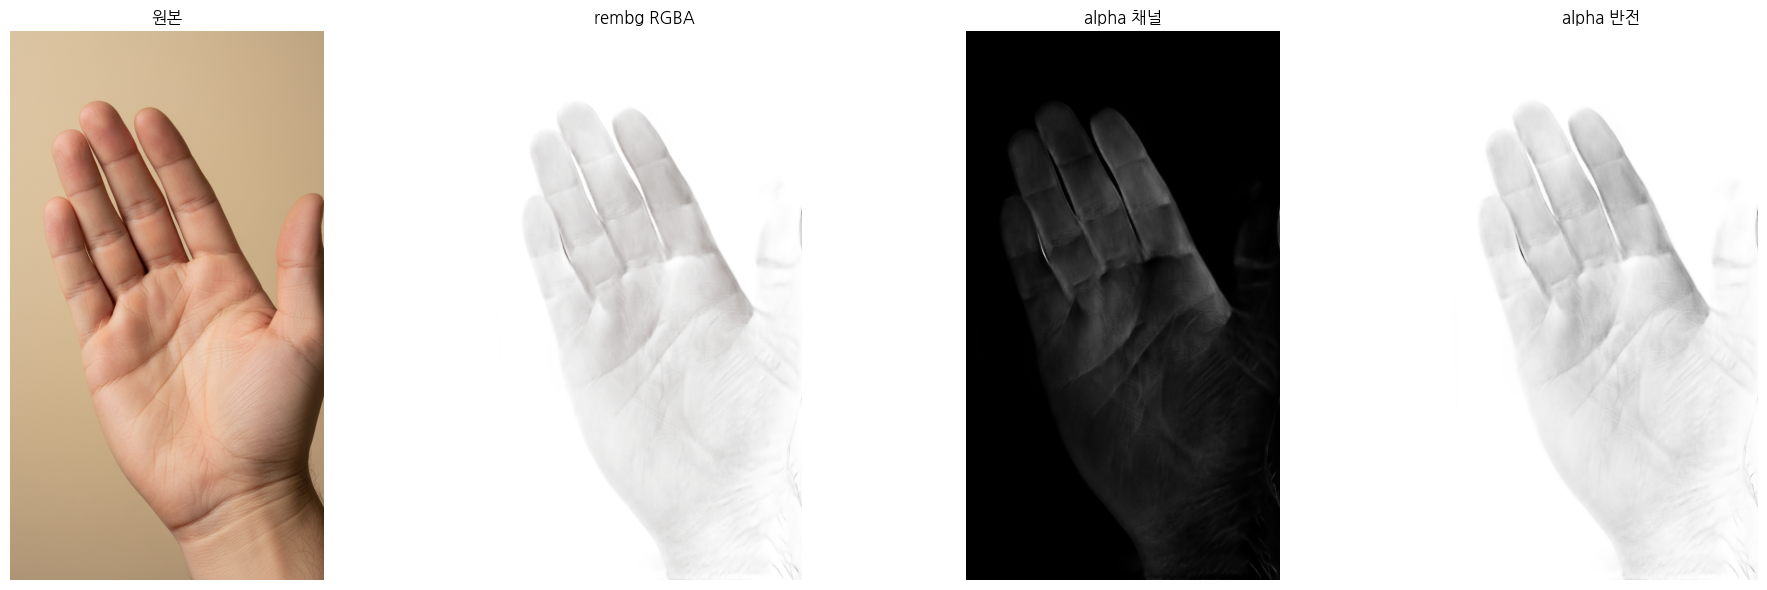

In [9]:
# palm_050 단일 재처리 + alpha 채널 분석
from rembg import remove
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

p = next(pp for pp in palm_paths if pp.stem == 'palm_050')
img = Image.open(p)
result = remove(img, session=session)
rgba = np.array(result)

print(f'alpha 통계:')
print(f'  alpha == 0  (완전 투명): {(rgba[:,:,3] == 0).sum() / rgba[:,:,3].size * 100:.1f}%')
print(f'  alpha > 128 (불투명):    {(rgba[:,:,3] > 128).sum() / rgba[:,:,3].size * 100:.1f}%')
print(f'  alpha mean: {rgba[:,:,3].mean():.1f}')

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
axes[0].imshow(img); axes[0].set_title('원본'); axes[0].axis('off')
axes[1].imshow(rgba); axes[1].set_title('rembg RGBA'); axes[1].axis('off')
axes[2].imshow(rgba[:,:,3], cmap='gray'); axes[2].set_title('alpha 채널'); axes[2].axis('off')
# 반전된 alpha
axes[3].imshow(255 - rgba[:,:,3], cmap='gray'); axes[3].set_title('alpha 반전'); axes[3].axis('off')
plt.tight_layout()
plt.show()

palm_050 반전 마스크 커버리지: 100.0%


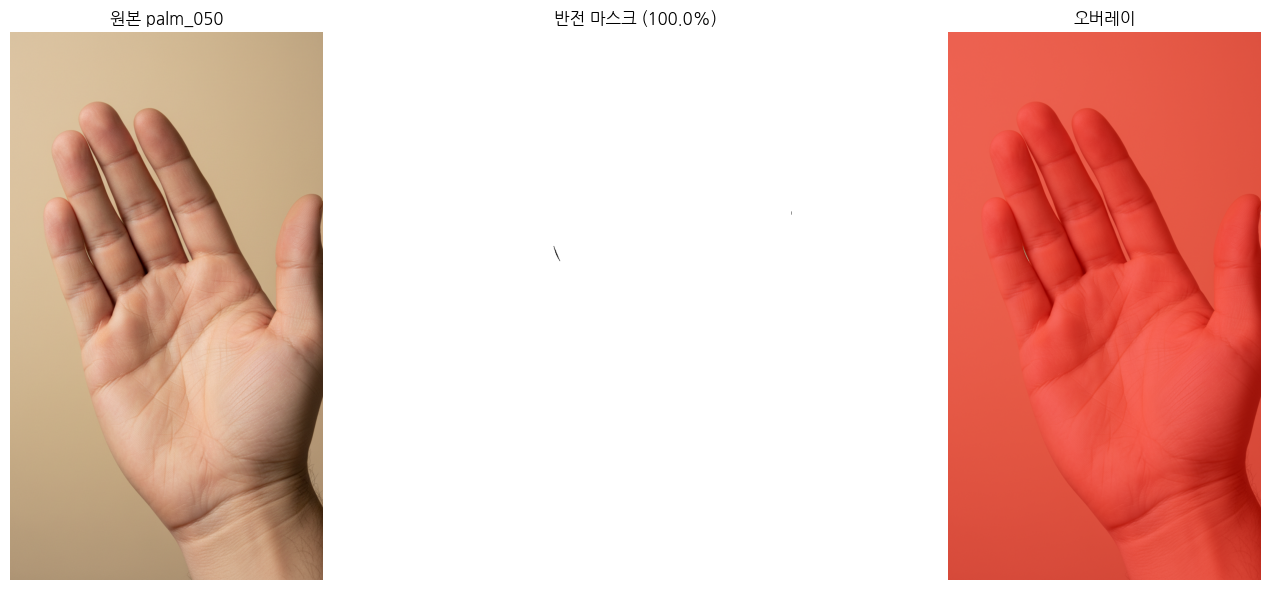

저장 완료: /content/palm_hand_masks/palm_050_mask.png

클로즈업 10장 전체 흰 마스크 저장 완료

총 11장 의심 케이스 처리:
  palm_050 (반전): 손 영역만 마스크
  palm_031~040, 043 (클로즈업): 전체 흰 마스크 (이미지 = 손)


In [10]:
# === palm_050: alpha 반전 (rembg가 손/배경 반대로 인식한 케이스)
import numpy as np
from PIL import Image
from rembg import remove

p = next(pp for pp in palm_paths if pp.stem == 'palm_050')
img = Image.open(p)
result = remove(img, session=session)
rgba = np.array(result)

# alpha 반전 후 binary 마스크
alpha_inv = 255 - rgba[:, :, 3]
mask_bin = (alpha_inv > 128).astype(np.uint8) * 255

coverage = (mask_bin == 255).sum() / mask_bin.size * 100
print(f'palm_050 반전 마스크 커버리지: {coverage:.1f}%')

# 시각 확인
import matplotlib.pyplot as plt
rgb = np.array(img.convert('RGB'))
overlay = rgb.copy()
overlay[mask_bin == 255] = (overlay[mask_bin == 255] * 0.5 + np.array([255, 0, 0]) * 0.5).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes[0].imshow(rgb); axes[0].set_title('원본 palm_050'); axes[0].axis('off')
axes[1].imshow(mask_bin, cmap='gray'); axes[1].set_title(f'반전 마스크 ({coverage:.1f}%)'); axes[1].axis('off')
axes[2].imshow(overlay); axes[2].set_title('오버레이'); axes[2].axis('off')
plt.tight_layout()
plt.show()

# 반전 마스크 저장
out_path = MASK_DIR / 'palm_050_mask.png'
Image.fromarray(mask_bin).save(out_path)
print(f'저장 완료: {out_path}')


# === 나머지 10장 (손금 매크로 클로즈업): 전체 흰 마스크 강제
suspicious_closeup = [
    'palm_033', 'palm_036', 'palm_032', 'palm_043',
    'palm_038', 'palm_040', 'palm_031', 'palm_034', 'palm_039', 'palm_037'
]

for stem in suspicious_closeup:
    p = next(pp for pp in palm_paths if pp.stem == stem)
    img = Image.open(p)
    w, h = img.size
    full_mask = np.full((h, w), 255, dtype=np.uint8)
    out_path = MASK_DIR / (stem + '_mask.png')
    Image.fromarray(full_mask).save(out_path)

print(f'\n클로즈업 10장 전체 흰 마스크 저장 완료')
print(f'\n총 11장 의심 케이스 처리:')
print(f'  palm_050 (반전): 손 영역만 마스크')
print(f'  palm_031~040, 043 (클로즈업): 전체 흰 마스크 (이미지 = 손)')

100%|███████████████████████████████████████| 176M/176M [00:00<00:00, 67.5GB/s]


EP Error /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:1193 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library libonnxruntime_providers_tensorrt.so with error: libcudnn.so.8: cannot open shared object file: No such file or directory
 when using ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']
Falling back to ['CUDAExecutionProvider', 'CPUExecutionProvider'] and retrying.


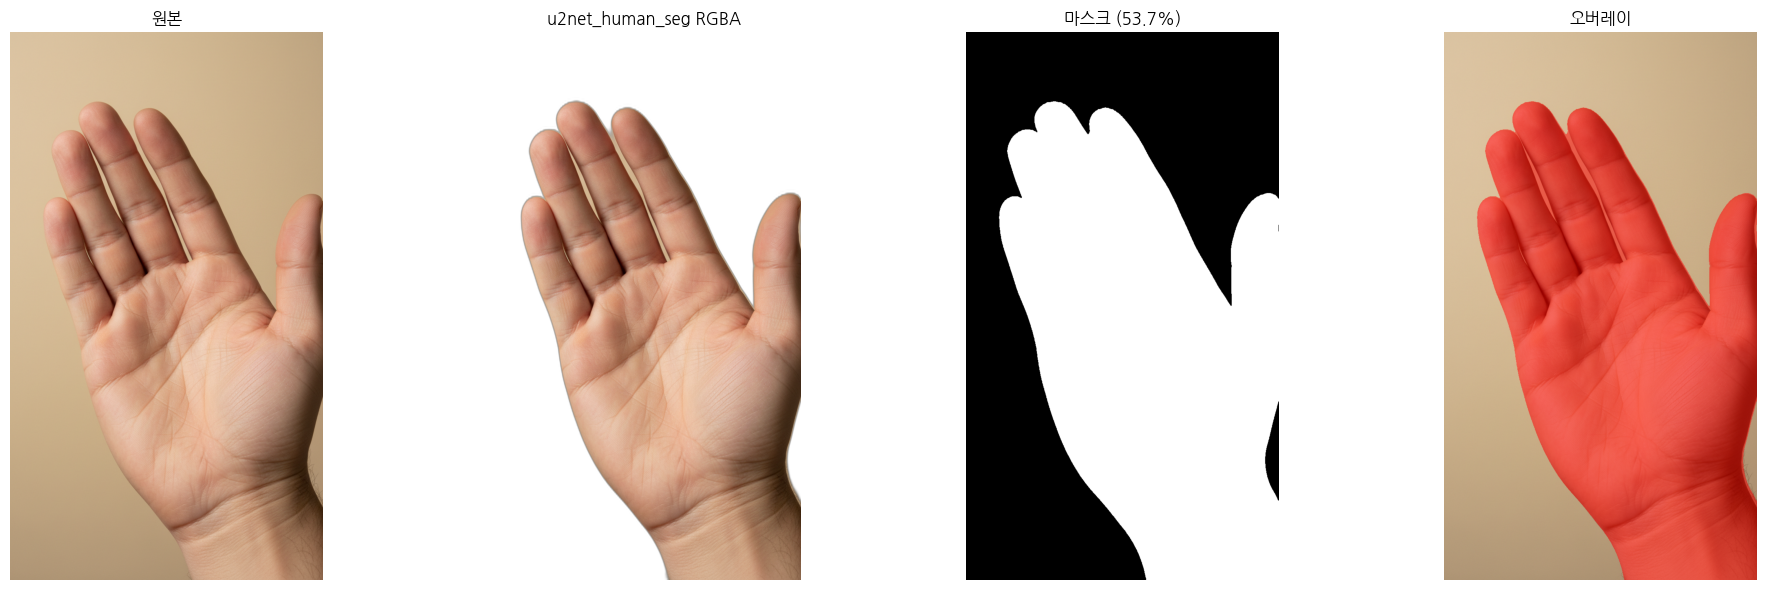


저장: /content/palm_hand_masks/palm_050_mask.png


In [11]:
# u2net_human_seg로 palm_050 재시도
from rembg import new_session, remove
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

session_human = new_session('u2net_human_seg')

p = next(pp for pp in palm_paths if pp.stem == 'palm_050')
img = Image.open(p)
result = remove(img, session=session_human)
rgba = np.array(result)
mask = rgba[:, :, 3]

mask_bin = (mask > 128).astype(np.uint8) * 255
coverage = (mask_bin == 255).sum() / mask_bin.size * 100

rgb = np.array(img.convert('RGB'))
overlay = rgb.copy()
overlay[mask_bin == 255] = (overlay[mask_bin == 255] * 0.5 + np.array([255, 0, 0]) * 0.5).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
axes[0].imshow(img); axes[0].set_title('원본'); axes[0].axis('off')
axes[1].imshow(rgba); axes[1].set_title('u2net_human_seg RGBA'); axes[1].axis('off')
axes[2].imshow(mask_bin, cmap='gray'); axes[2].set_title(f'마스크 ({coverage:.1f}%)'); axes[2].axis('off')
axes[3].imshow(overlay); axes[3].set_title('오버레이'); axes[3].axis('off')
plt.tight_layout()
plt.show()

if 30 < coverage < 70:
    out_path = MASK_DIR / 'palm_050_mask.png'
    Image.fromarray(mask_bin).save(out_path)
    print(f'\n저장: {out_path}')
else:
    print(f'\nu2net_human_seg 도 실패 → 100% 강제로 폴백')
    full_mask = np.full(mask_bin.shape, 255, dtype=np.uint8)
    Image.fromarray(full_mask).save(MASK_DIR / 'palm_050_mask.png')

In [12]:
# 11장 의심 케이스 u2net_human_seg로 재처리
from rembg import new_session, remove
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 세션은 이전 셀에서 만든 session_human 재사용 (없으면 다시 생성)
try:
    session_human
except NameError:
    session_human = new_session('u2net_human_seg')

suspicious_names = [
    'palm_050', 'palm_033', 'palm_036', 'palm_032', 'palm_043',
    'palm_038', 'palm_040', 'palm_031', 'palm_034', 'palm_039', 'palm_037'
]

results = []
for stem in suspicious_names:
    p = next(pp for pp in palm_paths if pp.stem == stem)
    img = Image.open(p)
    result = remove(img, session=session_human)
    rgba = np.array(result)
    mask_bin = (rgba[:, :, 3] > 128).astype(np.uint8) * 255
    coverage = (mask_bin == 255).sum() / mask_bin.size * 100
    results.append((stem, coverage, mask_bin, np.array(img.convert('RGB'))))
    print(f'  {stem}: {coverage:.1f}%')

# 시각화 (3열: 원본 / 마스크 / 오버레이)
n = len(results)
fig, axes = plt.subplots(n, 3, figsize=(15, 4 * n))
if n == 1:
    axes = axes.reshape(1, -1)

for i, (stem, c, mask, rgb) in enumerate(results):
    overlay = rgb.copy()
    overlay[mask == 255] = (overlay[mask == 255] * 0.5 + np.array([255, 0, 0]) * 0.5).astype(np.uint8)

    axes[i, 0].imshow(rgb);  axes[i, 0].set_title(f'원본 {stem}');           axes[i, 0].axis('off')
    axes[i, 1].imshow(mask, cmap='gray'); axes[i, 1].set_title(f'마스크 ({c:.1f}%)'); axes[i, 1].axis('off')
    axes[i, 2].imshow(overlay); axes[i, 2].set_title('오버레이');             axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig('/content/_viz_human_seg_retry.png', dpi=80, bbox_inches='tight')
plt.show()

# 자동 저장 결정 — 30~95% 범위면 정상
print(f'\n=== 저장 ===')
saved, fallback = [], []
for stem, c, mask, _ in results:
    out_path = MASK_DIR / (stem + '_mask.png')
    if 20 < c < 95:
        Image.fromarray(mask).save(out_path)
        saved.append(stem)
    else:
        # 폴백: 100% 강제
        h, w = mask.shape
        Image.fromarray(np.full((h, w), 255, dtype=np.uint8)).save(out_path)
        fallback.append(stem)

print(f'정상 저장 ({len(saved)}장): {saved}')
print(f'100% 강제 폴백 ({len(fallback)}장): {fallback}')

Output hidden; open in https://colab.research.google.com to view.

In [8]:
# 의심 케이스 (전체 손 클로즈업) → 마스크를 전체 흰으로 강제
import numpy as np
from PIL import Image

suspicious_names = [
    'palm_050', 'palm_033', 'palm_036', 'palm_032', 'palm_043',
    'palm_038', 'palm_040', 'palm_031', 'palm_034', 'palm_039', 'palm_037'
]

for stem in suspicious_names:
    p = next(pp for pp in palm_paths if pp.stem == stem)
    img = Image.open(p)
    h, w = img.size[1], img.size[0]
    # 전체 흰 마스크 (이미지 전체 = 손)
    full_mask = np.full((h, w), 255, dtype=np.uint8)
    out_path = MASK_DIR / (stem + '_mask.png')
    Image.fromarray(full_mask).save(out_path)
    print(f'  {stem}: 전체 흰 마스크 저장 ({w}×{h})')

print(f'\n완료. 11장 마스크 100% 덮어쓰기.')
print(f'합성 시 알약을 어디 놔도 손 위로 떨어짐 (이미지 전체가 손이므로).')

  palm_050: 전체 흰 마스크 저장 (768×1344)
  palm_033: 전체 흰 마스크 저장 (768×1344)
  palm_036: 전체 흰 마스크 저장 (768×1344)
  palm_032: 전체 흰 마스크 저장 (768×1344)
  palm_043: 전체 흰 마스크 저장 (768×1344)
  palm_038: 전체 흰 마스크 저장 (768×1344)
  palm_040: 전체 흰 마스크 저장 (768×1344)
  palm_031: 전체 흰 마스크 저장 (768×1344)
  palm_034: 전체 흰 마스크 저장 (768×1344)
  palm_039: 전체 흰 마스크 저장 (768×1344)
  palm_037: 전체 흰 마스크 저장 (768×1344)

완료. 11장 마스크 100% 덮어쓰기.
합성 시 알약을 어디 놔도 손 위로 떨어짐 (이미지 전체가 손이므로).


## 15. 검수 시각화 (12장)

In [13]:
n_show = 12
show_paths = palm_paths[:n_show]

fig, axes = plt.subplots(n_show, 3, figsize=(15, 4 * n_show))
for i, p in enumerate(show_paths):
    img = Image.open(p)
    rgb = np.array(img.convert('RGB'))
    mask_path = MASK_DIR / (p.stem + '_mask.png')
    mask = np.array(Image.open(mask_path))

    overlay = rgb.copy()
    if mask.shape != rgb.shape[:2]:
        mask = np.array(Image.fromarray(mask).resize((rgb.shape[1], rgb.shape[0])))
    overlay[mask == 255] = (overlay[mask == 255] * 0.5 + np.array([255, 0, 0]) * 0.5).astype(np.uint8)

    coverage = (mask == 255).sum() / mask.size * 100

    axes[i, 0].imshow(rgb);  axes[i, 0].set_title(f'원본 {p.stem}');             axes[i, 0].axis('off')
    axes[i, 1].imshow(mask, cmap='gray'); axes[i, 1].set_title(f'마스크 ({coverage:.1f}%)'); axes[i, 1].axis('off')
    axes[i, 2].imshow(overlay); axes[i, 2].set_title('오버레이');                  axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig('/content/_viz_first12.png', dpi=80, bbox_inches='tight')
plt.show()


Output hidden; open in https://colab.research.google.com to view.

## 16. 의심 케이스 시각화

In [ ]:
if not suspicious:
    print('의심 케이스 없음')
else:
    n = len(suspicious)
    fig, axes = plt.subplots(n, 3, figsize=(15, 4 * n))
    if n == 1:
        axes = axes.reshape(1, -1)
    for i, (stem, c) in enumerate(suspicious):
        p = next(pp for pp in palm_paths if pp.stem == stem)
        img = Image.open(p)
        rgb = np.array(img.convert('RGB'))
        mask = np.array(Image.open(MASK_DIR / (stem + '_mask.png')))
        overlay = rgb.copy()
        overlay[mask == 255] = (overlay[mask == 255] * 0.5 + np.array([255, 0, 0]) * 0.5).astype(np.uint8)

        axes[i, 0].imshow(rgb);  axes[i, 0].set_title(f'원본 {stem}');           axes[i, 0].axis('off')
        axes[i, 1].imshow(mask, cmap='gray'); axes[i, 1].set_title(f'마스크 ({c:.1f}%)'); axes[i, 1].axis('off')
        axes[i, 2].imshow(overlay); axes[i, 2].set_title('오버레이');             axes[i, 2].axis('off')
    plt.tight_layout()
    plt.savefig('/content/_viz_suspicious.png', dpi=80, bbox_inches='tight')
    plt.show()


## 17. 마스크 zip 다운로드

In [14]:
OUT_ZIP = '/content/palm_hand_masks.zip'

with zipfile.ZipFile(OUT_ZIP, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(MASK_DIR.glob('*_mask.png')):
        zf.write(p, arcname=p.name)

size_mb = os.path.getsize(OUT_ZIP) / (1024**2)
with zipfile.ZipFile(OUT_ZIP) as zf:
    n_files = len(zf.namelist())

print(f'zip: {OUT_ZIP}')
print(f'  크기:    {size_mb:.1f} MB')
print(f'  파일 수: {n_files}')
print(f'\n→ Colab 사이드바에서 palm_hand_masks.zip 다운로드')
print(f'→ 로컬 D:\\pill_detection\\synthetic_bg\\palm_hand_masks\\ 압축 해제')


zip: /content/palm_hand_masks.zip
  크기:    0.3 MB
  파일 수: 50

→ Colab 사이드바에서 palm_hand_masks.zip 다운로드
→ 로컬 D:\pill_detection\synthetic_bg\palm_hand_masks\ 압축 해제
